In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# Load the dataset
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")

# Parse the standardized features
df['Combined_Features'] = df['Combined_Features'].apply(eval)

# Convert features to a NumPy array
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0  # Penalize empty feature subsets
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy  # Minimize the inverse of accuracy

# Define the Lyrebird Optimization Algorithm with parallel processing
class LyrebirdOptimizer:
    def __init__(self, obj_func, dim, bounds, max_iter, population_size, n_jobs=4):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter
        self.population_size = population_size
        self.n_jobs = n_jobs
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.fitness = np.zeros(population_size)

    def evaluate_population(self):
        with ThreadPoolExecutor(max_workers=self.n_jobs) as executor:
            self.fitness = np.array(list(executor.map(self.obj_func, self.population)))

    def update_position(self, ind, iter_num):
        # Exploration phase: simulate escape strategy
        if np.random.rand() < 0.5:
            return ind + np.random.uniform(-1, 1, self.dim) * (1 - iter_num / self.max_iter)
        # Exploitation phase: simulate hiding strategy
        else:
            return ind + np.random.normal(0, 0.1, self.dim)

    def optimize(self):
        self.evaluate_population()
        best_idx = np.argmin(self.fitness)
        best_sol = self.population[best_idx]
        best_fit = self.fitness[best_idx]

        for iter_num in tqdm(range(self.max_iter), desc="Optimizing"):
            for i in range(self.population_size):
                new_pos = self.update_position(self.population[i], iter_num)
                new_pos = np.clip(new_pos, self.bounds[0], self.bounds[1])
                self.population[i] = new_pos

            self.evaluate_population()
            best_idx = np.argmin(self.fitness)
            if self.fitness[best_idx] < best_fit:
                best_sol = self.population[best_idx]
                best_fit = self.fitness[best_idx]

        return best_sol, best_fit

# Set parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20
n_jobs = 8  # Number of parallel workers

# Initialize and run the optimizer
lo = LyrebirdOptimizer(objective_function, dim, bounds, max_iter, population_size, n_jobs=n_jobs)
best_mask, best_fitness = lo.optimize()

# Extract the selected features
selected_features = np.where(best_mask > 0.5)[0]
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save the new CSV
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('Lyrebird_selected_features.csv', index=False)

print("Feature selection completed and new dataset saved!")

Optimizing: 100%|██████████| 100/100 [02:53<00:00,  1.74s/it]

Feature selection completed and new dataset saved!


In [2]:
import pandas as pd

# Load original and selected datasets
original_df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_df = pd.read_csv('Lyrebird_selected_features.csv')

# Extract and count features
original_features_count = len(eval(original_df['Combined_Features'][0]))
selected_features_count = len(eval(selected_df['Selected_Features'][0]))

# Compare number of features
print(f"Original number of features: {original_features_count}")
print(f"Selected number of features: {selected_features_count}")

reduction_percentage = ((original_features_count - selected_features_count) / original_features_count) * 100
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 199
Selected number of features: 91
Feature reduction: 54.27%


# ML

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("Lyrebird_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.7927461139896373
Precision: 0.8005353159455997
Recall: 0.7927461139896373
F1 Score: 0.7923352712199341
Confusion Matrix:
 [[32  3  1  0  4  0]
 [ 1 23  0  0  3  0]
 [11  0 20  1  1  0]
 [ 0  0  2 31  0  0]
 [ 1  0  1  0 21  7]
 [ 1  0  0  0  3 26]]


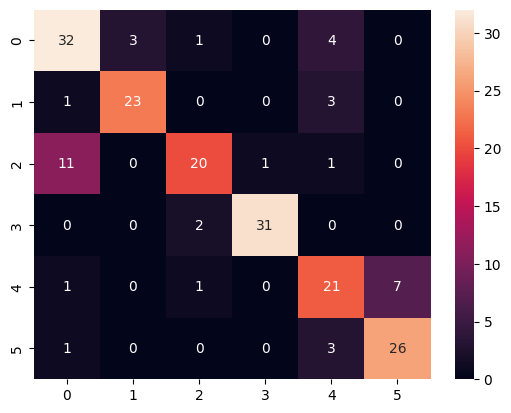

In [2]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.8963730569948186
Precision: 0.8995512583271651
Recall: 0.8963730569948186
F1 Score: 0.897197338159476
Confusion Matrix:
 [[36  0  4  0  0  0]
 [ 0 24  1  0  2  0]
 [ 4  0 27  1  1  0]
 [ 0  0  2 31  0  0]
 [ 0  0  1  0 26  3]
 [ 0  0  0  0  1 29]]


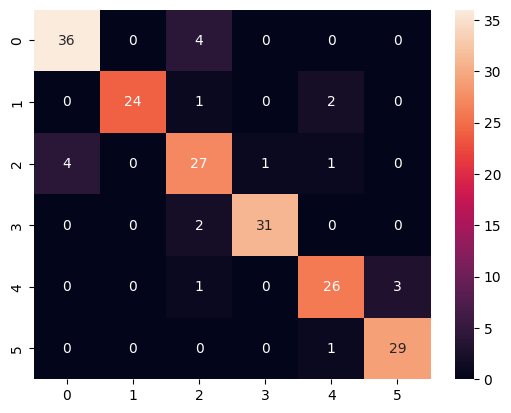

In [3]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.7512953367875648
Precision: 0.7643142034373156
Recall: 0.7512953367875648
F1 Score: 0.754647427139148
Confusion Matrix:
 [[23  3 13  0  1  0]
 [ 1 22  1  0  1  2]
 [10  1 22  0  0  0]
 [ 0  0  4 29  0  0]
 [ 0  1  2  0 23  4]
 [ 0  0  0  0  4 26]]


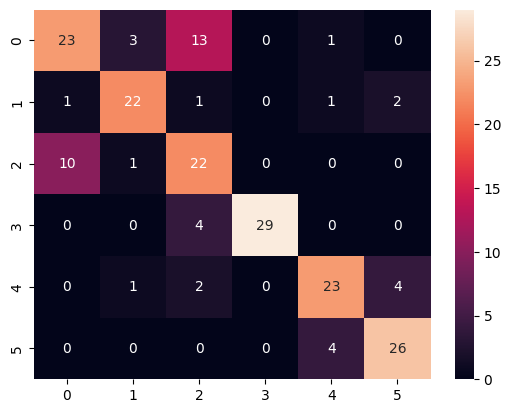

In [4]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.8652849740932642
Precision: 0.868530699427305
Recall: 0.8652849740932642
F1 Score: 0.8656309888013627
Confusion Matrix:
 [[36  1  2  0  1  0]
 [ 0 24  1  0  2  0]
 [ 5  0 27  1  0  0]
 [ 0  0  3 30  0  0]
 [ 0  0  3  0 22  5]
 [ 0  0  0  0  2 28]]


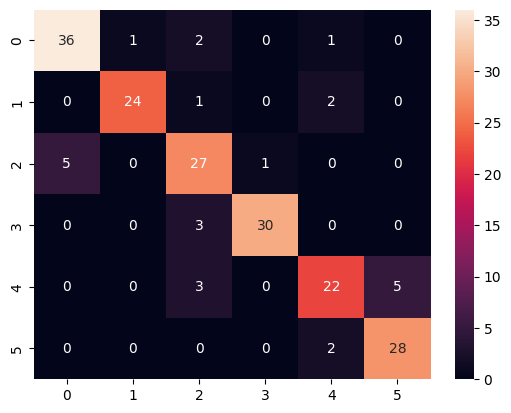

In [5]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-21 18:23:50.717303: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2025-03-21 18:23:50.717340: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-21 18:23:50.717346: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-21 18:23:50.717366: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-21 18:23:50.717377: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - accuracy: 0.8362 - loss: 0.5118
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.8497409326424871
Precision: 0.8554604150401324
Recall: 0.8497409326424871
F1 Score: 0.8490947643838167
Confusion Matrix:
 [[28  0 12  0  0  0]
 [ 1 24  0  0  1  1]
 [ 5  0 26  2  0  0]
 [ 0  0  0 33  0  0]
 [ 0  0  0  0 29  1]
 [ 0  1  0  0  5 24]]


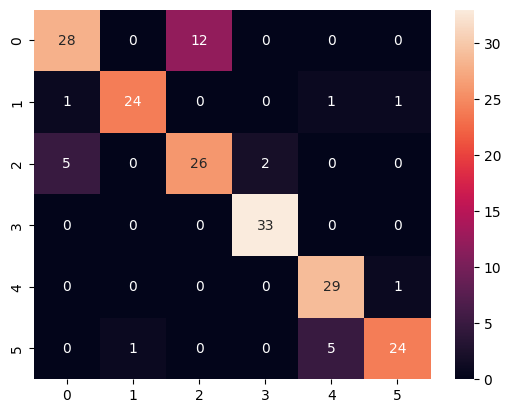

In [6]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8502 - loss: 0.4455
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.8756476683937824
Precision: 0.8863684387000449
Recall: 0.8756476683937824
F1 Score: 0.8744585339396334
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 2 22  1  0  2  0]
 [ 9  0 22  1  1  0]
 [ 0  0  1 32  0  0]
 [ 0  0  0  0 29  1]
 [ 1  0  0  0  3 26]]


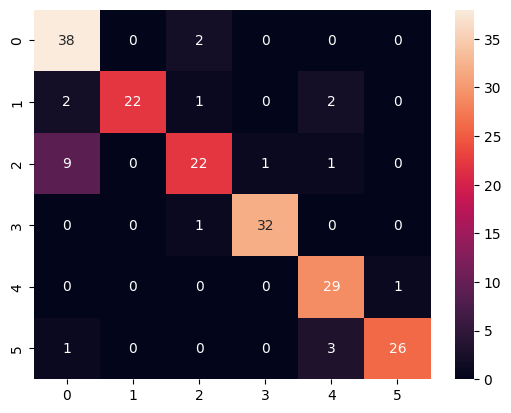

In [7]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)

# Reinforced

### Adaptive Transition Between Exploration & Exploitation:
Instead of a fixed 0.5 split, let’s gradually transition based on iterations. Early iterations focus on exploration, later ones on exploitation.
### Elite Preservation:
Keep track of the top few solutions and ensure they survive every iteration. This avoids losing promising solutions to randomness.
### Dynamic Step Size:
The step size in the update function could adapt based on population diversity or fitness stagnation to prevent premature convergence.
### Mutation Mechanism (Inspiration from Evolutionary Algorithms):
Occasionally, apply a mutation (e.g., Gaussian noise or a random jump) to avoid local minima.
### Momentum-based Update (Inspiration from Particle Swarm Optimization):
Carry forward a portion of the previous update direction to maintain momentum and speed up convergence.
### Fitness-Based Adaptation:
Solutions closer to the best fitness could exploit more, while worse ones explore more — promoting a natural selection effect.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# Load the dataset
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")

# Parse the standardized features
df['Combined_Features'] = df['Combined_Features'].apply(eval)

# Convert features to a NumPy array
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0  # Penalize empty feature subsets
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy  # Minimize the inverse of accuracy

# Reinforced Lyrebird Optimization Algorithm
class ReinforcedLyrebirdOptimizer:
    def __init__(self, obj_func, dim, bounds, max_iter, population_size, n_jobs=4):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter
        self.population_size = population_size
        self.n_jobs = n_jobs
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.fitness = np.zeros(population_size)
        self.best_solution = None
        self.best_fitness = float('inf')
        self.elite_fraction = 0.1

    def evaluate_population(self):
        with ThreadPoolExecutor(max_workers=self.n_jobs) as executor:
            self.fitness = np.array(list(executor.map(self.obj_func, self.population)))

    def adapt_phase(self, iter_num):
        # Adaptive exploration-exploitation transition
        return np.random.rand() < (1 - iter_num / self.max_iter)

    def mutate(self, ind):
        # Mutation mechanism to avoid local minima
        if np.random.rand() < 0.1:
            return ind + np.random.normal(0, 0.05, self.dim)
        return ind

    def update_position(self, ind, iter_num):
        if self.adapt_phase(iter_num):
            # Exploration (early stage)
            return ind + np.random.uniform(-1, 1, self.dim) * (1 - iter_num / self.max_iter)
        else:
            # Exploitation (later stage) with momentum
            momentum = 0.9 * (ind - self.best_solution)
            return ind + np.random.normal(0, 0.1, self.dim) + momentum

    def preserve_elite(self):
        elite_size = int(self.population_size * self.elite_fraction)
        elite_indices = np.argsort(self.fitness)[:elite_size]
        return self.population[elite_indices]

    def optimize(self):
        self.evaluate_population()
        best_idx = np.argmin(self.fitness)
        self.best_solution = self.population[best_idx]
        self.best_fitness = self.fitness[best_idx]

        for iter_num in tqdm(range(self.max_iter), desc="Reinforced Optimizing"):
            elite = self.preserve_elite()
            
            for i in range(self.population_size):
                new_pos = self.update_position(self.population[i], iter_num)
                new_pos = self.mutate(np.clip(new_pos, self.bounds[0], self.bounds[1]))
                self.population[i] = new_pos

            self.evaluate_population()
            best_idx = np.argmin(self.fitness)
            if self.fitness[best_idx] < self.best_fitness:
                self.best_solution = self.population[best_idx]
                self.best_fitness = self.fitness[best_idx]

            # Ensure elite solutions stay in population
            self.population[:len(elite)] = elite

        return self.best_solution, self.best_fitness

# Set parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20
n_jobs = 8  # Number of parallel workers

# Initialize and run the optimizer
rlo = ReinforcedLyrebirdOptimizer(objective_function, dim, bounds, max_iter, population_size, n_jobs=n_jobs)
best_mask, best_fitness = rlo.optimize()

# Extract the selected features
selected_features = np.where(best_mask > 0.5)[0]
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save the new CSV
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('Reinforced_Lyrebird_selected_features.csv', index=False)

print("Reinforced feature selection completed and new dataset saved!")

Reinforced Optimizing: 100%|██████████| 100/100 [02:54<00:00,  1.74s/it]

Reinforced feature selection completed and new dataset saved!


In [2]:
import pandas as pd

# Load original and selected datasets
original_df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_df = pd.read_csv('Reinforced_Lyrebird_selected_features.csv')

# Extract and count features
original_features_count = len(eval(original_df['Combined_Features'][0]))
selected_features_count = len(eval(selected_df['Selected_Features'][0]))

# Compare number of features
print(f"Original number of features: {original_features_count}")
print(f"Selected number of features: {selected_features_count}")

reduction_percentage = ((original_features_count - selected_features_count) / original_features_count) * 100
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 199
Selected number of features: 101
Feature reduction: 49.25%


# ML

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("Reinforced_Lyrebird_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.8134715025906736
Precision: 0.8208090625301708
Recall: 0.8134715025906736
F1 Score: 0.811737226504066
Confusion Matrix:
 [[33  4  0  0  3  0]
 [ 0 24  0  0  3  0]
 [10  0 21  1  1  0]
 [ 0  0  1 32  0  0]
 [ 1  0  1  0 20  8]
 [ 0  0  0  0  3 27]]


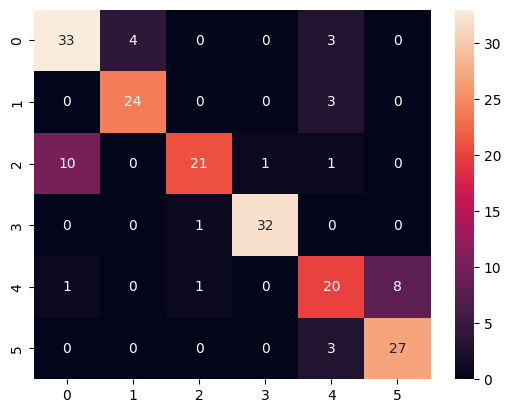

In [2]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.8652849740932642
Precision: 0.8668376660115538
Recall: 0.8652849740932642
F1 Score: 0.8655434990568911
Confusion Matrix:
 [[35  1  4  0  0  0]
 [ 0 24  1  0  2  0]
 [ 6  0 25  1  1  0]
 [ 0  0  2 31  0  0]
 [ 1  0  1  0 24  4]
 [ 0  0  0  0  2 28]]


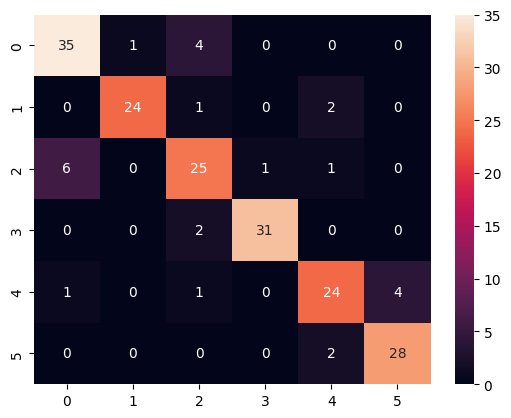

In [3]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.7927461139896373
Precision: 0.7947239206964023
Recall: 0.7927461139896373
F1 Score: 0.7923534680269011
Confusion Matrix:
 [[25  2 10  0  3  0]
 [ 2 22  0  0  1  2]
 [ 8  1 23  1  0  0]
 [ 1  0  2 30  0  0]
 [ 2  0  0  0 24  4]
 [ 0  0  0  0  1 29]]


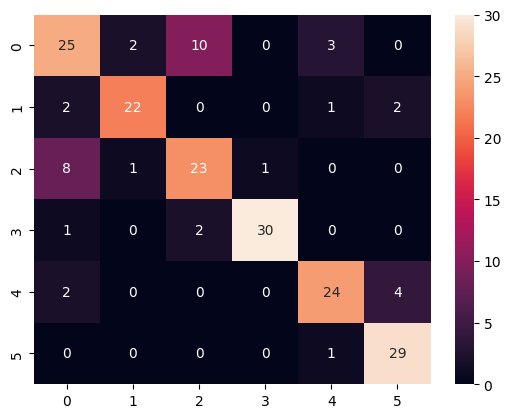

In [4]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.8911917098445595
Precision: 0.89287696780071
Recall: 0.8911917098445595
F1 Score: 0.8917551982661762
Confusion Matrix:
 [[36  1  2  0  1  0]
 [ 0 25  0  0  2  0]
 [ 3  0 29  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  2  0 24  4]
 [ 0  0  0  0  3 27]]


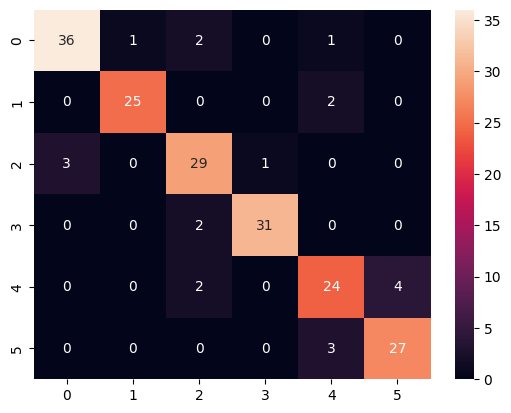

In [5]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-21 18:46:19.834124: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2025-03-21 18:46:19.834158: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-21 18:46:19.834163: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-21 18:46:19.834180: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-21 18:46:19.834192: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8589 - loss: 0.4520
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.8808290155440415
Precision: 0.8855732389123135
Recall: 0.8808290155440415
F1 Score: 0.8787708870443657
Confusion Matrix:
 [[34  2  4  0  0  0]
 [ 0 26  0  0  1  0]
 [ 4  0 27  1  1  0]
 [ 0  0  1 32  0  0]
 [ 0  1  0  0 21  8]
 [ 0  0  0  0  0 30]]


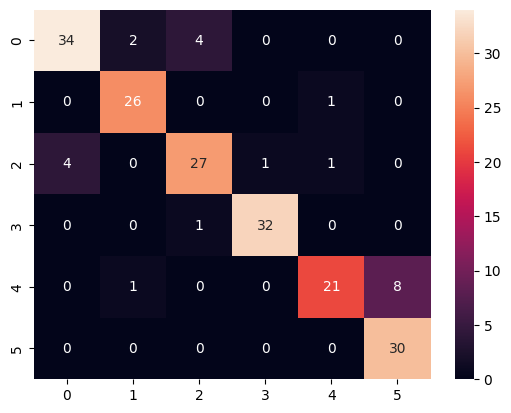

In [6]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8506 - loss: 0.4697
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.8860103626943006
Precision: 0.8886805820281108
Recall: 0.8860103626943006
F1 Score: 0.8866985968344709
Confusion Matrix:
 [[34  1  5  0  0  0]
 [ 0 24  1  0  2  0]
 [ 4  1 27  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  1  0 26  3]
 [ 0  0  0  0  1 29]]


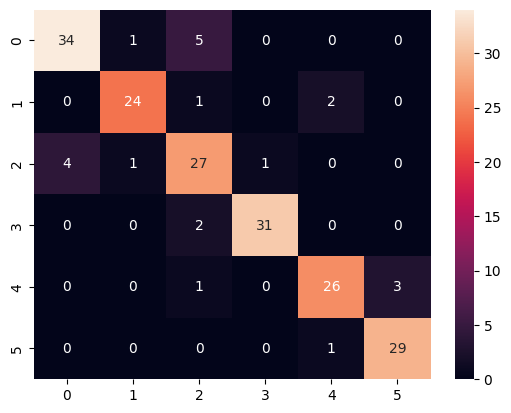

In [7]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)